# ML Zoomcamp 2026 — Homework 3: Classification

**Objective:** Lead scoring classification using the pinned 2026 dataset (`course_lead_scoring_2026.csv`).

Target variable: `converted`.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, mutual_info_score
from sklearn.model_selection import train_test_split

DATA_PATH = "course_lead_scoring_2026.csv"


## Load and explore the dataset

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
print("Columns:", list(df.columns))
print(df.dtypes)
print("Missing values:")
print(df.isna().sum())
print("Target distribution:")
print(df["converted"].value_counts())


Shape: (5000, 9)


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


Columns: ['lead_source', 'industry', 'employment_status', 'location', 'annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score', 'converted']
lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object
Missing values:
lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64
Target distribution:
converted
1    2883
0    2117
Name: count, dtype: int64


## Missing-value treatment

In [3]:
target = "converted"
feature_cols = [c for c in df.columns if c != target]

cat_cols = df[feature_cols].select_dtypes(include=["object", "string"]).columns.tolist()
num_cols = df[feature_cols].select_dtypes(include=[np.number]).columns.tolist()

for col in cat_cols:
    df[col] = df[col].fillna("NA")
for col in num_cols:
    df[col] = df[col].fillna(0.0)

print("Categorical:", cat_cols)
print("Numerical:", num_cols)


Categorical: ['lead_source', 'industry', 'employment_status', 'location']
Numerical: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


## Question 1 — Industry mode

In [4]:
industry_freq = df["industry"].value_counts()
print(industry_freq)
q1_answer = df["industry"].mode().iloc[0]
print("Q1 answer:", q1_answer)


industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
NA                240
Name: count, dtype: int64
Q1 answer: technology


## Question 2 — Correlation matrix and heatmap

,annual_income,number_of_courses_viewed,interaction_count,lead_score
annual_income,1.0000,0.1613,0.1228,0.2295
number_of_courses_viewed,0.1613,1.0000,0.7216,0.7572
interaction_count,0.1228,0.7216,1.0000,0.9157
lead_score,0.2295,0.7572,0.9157,1.0000


interaction_count and lead_score: 0.915746
number_of_courses_viewed and lead_score: 0.757204
number_of_courses_viewed and interaction_count: 0.721609
annual_income and interaction_count: 0.122842
Q2 answer: interaction_count and lead_score 0.9157457980418697


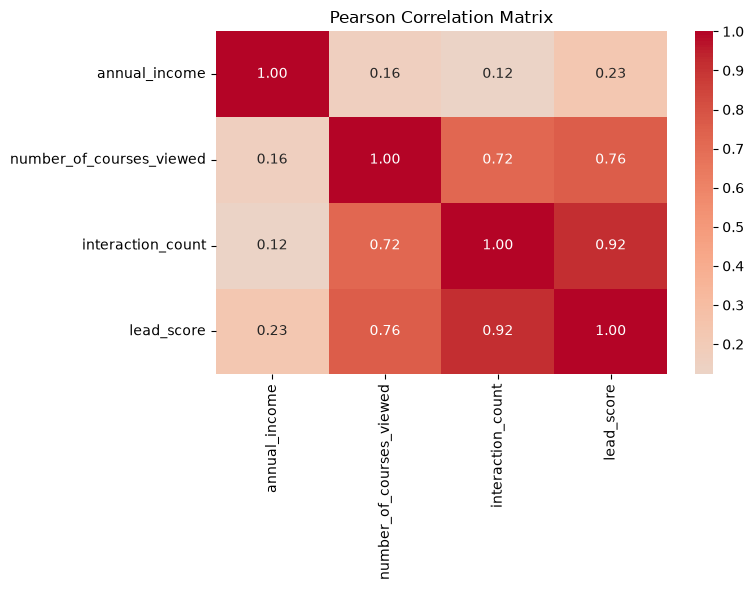

In [5]:
corr = df[num_cols].corr(method="pearson")
display(corr.round(4))

pairs = [
    ("interaction_count", "lead_score"),
    ("number_of_courses_viewed", "lead_score"),
    ("number_of_courses_viewed", "interaction_count"),
    ("annual_income", "interaction_count"),
]
labels = [
    "interaction_count and lead_score",
    "number_of_courses_viewed and lead_score",
    "number_of_courses_viewed and interaction_count",
    "annual_income and interaction_count",
]

best_label, best_val = None, -np.inf
for (a, b), label in zip(pairs, labels):
    val = corr.loc[a, b]
    print(f"{label}: {val:.6f}")
    if val > best_val:
        best_val, best_label = val, label

print("Q2 answer:", best_label, best_val)

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Pearson Correlation Matrix")
plt.tight_layout()
plt.show()


## Train / validation / test split

In [6]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

y_train = df_train["converted"]
y_val = df_val["converted"]
y_test = df_test["converted"]

X_train = df_train.drop(columns=["converted"])
X_val = df_val.drop(columns=["converted"])
X_test = df_test.drop(columns=["converted"])

print(len(df_train), len(df_val), len(df_test))
assert "converted" not in X_train.columns


3000 1000 1000


## Question 3 — Mutual information (training set only)

In [7]:
mi_rows = []
for col in cat_cols:
    score = mutual_info_score(df_train["converted"], df_train[col])
    mi_rows.append({"feature": col, "mi": score, "mi_rounded": round(score, 2)})

mi_df = pd.DataFrame(mi_rows).sort_values("mi", ascending=False)
display(mi_df)

compare = ["industry", "location", "lead_source", "employment_status"]
q3_answer = max(compare, key=lambda c: mutual_info_score(df_train["converted"], df_train[c]))
print("Q3 answer:", q3_answer)


,feature,mi,mi_rounded
0,lead_source,0.034346,0.03
2,employment_status,0.018966,0.02
1,industry,0.001995,0.00
3,location,0.001043,0.00


Q3 answer: lead_source


## Question 4 — Logistic regression

In [8]:
def train_lr(X_tr, X_va, y_tr, y_va, C=1.0):
    dv = DictVectorizer(sparse=False)
    X_tr_enc = dv.fit_transform(X_tr.to_dict(orient="records"))
    X_va_enc = dv.transform(X_va.to_dict(orient="records"))
    model = LogisticRegression(solver="liblinear", C=C, max_iter=1000, random_state=42)
    model.fit(X_tr_enc, y_tr)
    y_pred = model.predict(X_va_enc)
    return accuracy_score(y_va, y_pred)

baseline_acc = train_lr(X_train, X_val, y_train, y_val, C=1.0)
q4_rounded = round(baseline_acc, 2)
print("Raw:", baseline_acc, "Rounded:", q4_rounded)


Raw: 0.645 Rounded: 0.65


## Question 5 — Feature elimination

In [9]:
candidates = ["lead_source", "number_of_courses_viewed", "interaction_count"]
rows = []
for feat in candidates:
    acc = train_lr(X_train.drop(columns=[feat]), X_val.drop(columns=[feat]), y_train, y_val)
    rows.append({
        "removed": feat,
        "baseline": baseline_acc,
        "without": acc,
        "difference": baseline_acc - acc,
    })

fe_df = pd.DataFrame(rows)
display(fe_df)
q5_answer = fe_df.loc[fe_df["difference"].idxmin(), "removed"]
print("Q5 answer:", q5_answer)


,removed,baseline,without,difference
0,lead_source,0.645,0.642,0.003
1,number_of_courses_viewed,0.645,0.643,0.002
2,interaction_count,0.645,0.601,0.044


Q5 answer: number_of_courses_viewed


## Question 6 — Regularization

In [10]:
C_values = [0.000001, 0.00001, 0.0001, 0.001]
reg_rows = []
for C in C_values:
    acc = train_lr(X_train, X_val, y_train, y_val, C=C)
    reg_rows.append({"C": C, "accuracy": acc, "rounded_3": round(acc, 3)})

reg_df = pd.DataFrame(reg_rows)
display(reg_df)

best_rounded = reg_df["rounded_3"].max()
q6_answer = reg_df[reg_df["rounded_3"] == best_rounded]["C"].min()
print("Q6 answer:", q6_answer)


,C,accuracy,rounded_3
0,0.000001,0.598,0.598
1,0.000010,0.598,0.598
2,0.000100,0.613,0.613
3,0.001000,0.645,0.645


Q6 answer: 0.001


## Final answers

| Q | Answer |
|---|--------|
| 1 | technology |
| 2 | interaction_count and lead_score |
| 3 | lead_source |
| 4 | 0.65 |
| 5 | number_of_courses_viewed |
| 6 | 0.001 |
